#### Task 5: Boxplot of weekly screen time for 8 weeks, with outliers highlighted.

Q1 = 28.12, Q3 = 30.75, IQR = 2.62, fences = (24.19, 34.69)
Outlier: week 6 with 48.0 hours


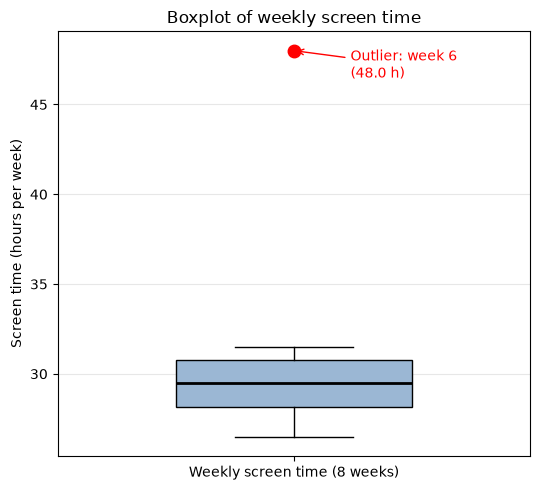

Plot saved to screen_time_boxplot.png


In [2]:
import os
import numpy as np
import matplotlib
if "__file__" in globals():            # plain script: save to file; notebook: show inline
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
 
HERE = os.path.dirname(os.path.abspath(__file__)) if "__file__" in globals() else os.getcwd()
 
screen_time = np.array([28.5, 30, 27, 31.5, 29, 48, 26.5, 30.5])         # hours per week, weeks 1-8
weeks = np.arange(1, 9)
 
q1, q3 = np.percentile(screen_time, [25, 75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
is_out = (screen_time < lower) | (screen_time > upper)
print(f"Q1 = {q1:.2f}, Q3 = {q3:.2f}, IQR = {iqr:.2f}, fences = ({lower:.2f}, {upper:.2f})")
for w, v in zip(weeks[is_out], screen_time[is_out]):
    print(f"Outlier: week {w} with {v} hours")
 
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.boxplot(screen_time, widths=0.5, patch_artist=True,
           boxprops=dict(facecolor="#9bb7d4"), medianprops=dict(color="black", lw=2),
           flierprops=dict(marker="o", markerfacecolor="red", markeredgecolor="red", markersize=9))
for w, v in zip(weeks[is_out], screen_time[is_out]):
    ax.annotate(f"Outlier: week {w}\n({v} h)", xy=(1, v), xytext=(1.12, v - 1.5), color="red",
                arrowprops=dict(arrowstyle="->", color="red"))
ax.set_xticks([1]); ax.set_xticklabels(["Weekly screen time (8 weeks)"])
ax.set_ylabel("Screen time (hours per week)")
ax.set_title("Boxplot of weekly screen time")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(HERE, "screen_time_boxplot.png"), dpi=150)
if "__file__" not in globals():
    plt.show()
print("Plot saved to screen_time_boxplot.png")